# FlowLens Gate 3｜分发诊断与推荐基线

## tl;dr

- 在标准曝光测试集的固定候选上，`MultiTaskHashSGD` 的 NDCG@5 为 **0.6236**，高于 ItemCF 的 **0.5983** 和 Popularity 的 **0.5869**。
- 在随机曝光敏感性集上，排序反转为 **ItemCF > Popularity > MultiTaskHashSGD**；这说明离线结论受日志采样与原策略选择偏差影响，不能把某一模型称为普适最优。
- 供需侧，标签 39 的历史需求份额比测试曝光份额高 **5.85 个百分点**；效率侧，标签 2 的曝光份额比消费份额高 **1.42 个百分点**，而标签 12 的差值较小但曝光规模更大。
- 泄漏检查 PASS；故意注入的未来长播率特征被三条规则拒绝。独立校验 13/13 项通过。

> 证据边界：以下均为公开日志上的 E3 离线回放证据，不是真实平台内部数据、线上 A/B 结果或因果增量。

## Context & Methods

目标是完成从“问题定位 → 基线比较 → 偏差识别 → 策略假设”的最小闭环，把数据分析、策略设计与实验判断连接为可复现的推荐分发决策过程。

### Key assumptions

- 训练窗为 2022-04-09 至 04-17，验证窗为 04-18 至 04-21，测试窗为 04-22 至 05-08。
- 每个评估用户的候选集是评估窗内真实出现的去重用户—视频对，因此衡量 logged-exposure reranking，而不是全目录召回。
- `long_view` 是主相关性标签；NDCG、MRR、AUC 与 ECR 均为离线描述，不等同于线上满意度或业务收益。
- 随机曝光日志只用于检查采样机制敏感性，不与标准曝光日志做因果效果对比。
- 数字标签缺少公开业务语义，只能称为 tag ID。

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "reports" / "gate3").exists() else cwd.parent
REPORT_DIR = PROJECT_ROOT / "reports" / "gate3"

metrics = pd.read_csv(REPORT_DIR / "baseline_metrics.csv")
tags = pd.read_csv(REPORT_DIR / "tag_supply_demand.csv")
daily = pd.read_csv(REPORT_DIR / "daily_standard_test.csv")
split_manifest = json.loads((REPORT_DIR / "split_manifest.json").read_text(encoding="utf-8"))
guardrails = json.loads((REPORT_DIR / "guardrails.json").read_text(encoding="utf-8"))
leakage = json.loads((REPORT_DIR / "leakage_report.json").read_text(encoding="utf-8"))
validation = json.loads((REPORT_DIR / "validation_summary.json").read_text(encoding="utf-8"))
run = json.loads((REPORT_DIR / "run_manifest.json").read_text(encoding="utf-8"))

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9.5, 5.2),
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.edgecolor": "#334155",
    "text.color": "#172033",
    "axes.labelcolor": "#172033",
})
COLORS = {"Popularity": "#8B95A5", "ItemCF": "#2457A6", "MultiTaskHashSGD": "#D6A328"}

## Data and integrity gates

本 Notebook 读取 Gate 3 运行脚本生成的紧凑证据文件；原始行级得分和逐用户明细由脚本复现，不嵌入 HTML。运行血缘、数据窗和结论边界保存在 `run_manifest.json`。

In [2]:
assert run["status"] == "VALID"
assert run["evidence_level"] == "E3"
assert leakage["status"] == "PASS"
assert validation["status"] == "PASS"
assert all(item["status"] == "PASS" for item in validation["checks"])

split_table = pd.DataFrame(split_manifest).T.reset_index(names="split")
split_table["long_view_rate"] = split_table["long_view_rate"].map(lambda x: f"{x:.2%}")
display(split_table)
display(pd.DataFrame(validation["checks"]))

,split,rows,users,videos,date_min,date_max,long_view_rate
0,train,1041093.0,25887.0,7530.0,20220409.0,20220417.0,34.13%
1,validation,84410.0,19219.0,5556.0,20220418.0,20220421.0,32.45%
2,standard_test,289119.0,25877.0,6618.0,20220422.0,20220508.0,31.83%
3,random_sensitivity,1186049.0,27285.0,7583.0,20220422.0,20220508.0,8.50%


,check,status,detail
0,required_artifacts_exist,PASS,missing=[]
1,model_split_matrix_complete,PASS,"rows=9, pairs=9"
2,user_level_metrics_recompute,PASS,maximum_absolute_difference=3.331e-16
3,metrics_within_unit_interval,PASS,columns=18
4,bootstrap_ci_contains_estimate,PASS,all 9 rows checked
5,strict_time_order,PASS,train < validation < standard_test
6,leakage_suite_and_negative_control,PASS,"status=PASS, injected_rejections=['forbidden_s..."
7,tag_shares_reconcile,PASS,"supply_share_error=4.00e-15, demand_share_erro..."
8,daily_test_window_complete,PASS,"days=17, rows=289119"
9,sampling_sensitivity_detected,PASS,"standard=['MultiTaskHashSGD', 'ItemCF', 'Popul..."


## Results

### 1. 模型表现依赖日志采样机制

标准曝光和随机曝光使用相同训练历史、同一模型与同一指标定义，但候选与标签分布不同。MultiTaskHashSGD 在标准曝光集领先，在随机曝光敏感性集却落后；因此 Gate 4 必须同时观察两类日志，不能只挑有利切片。

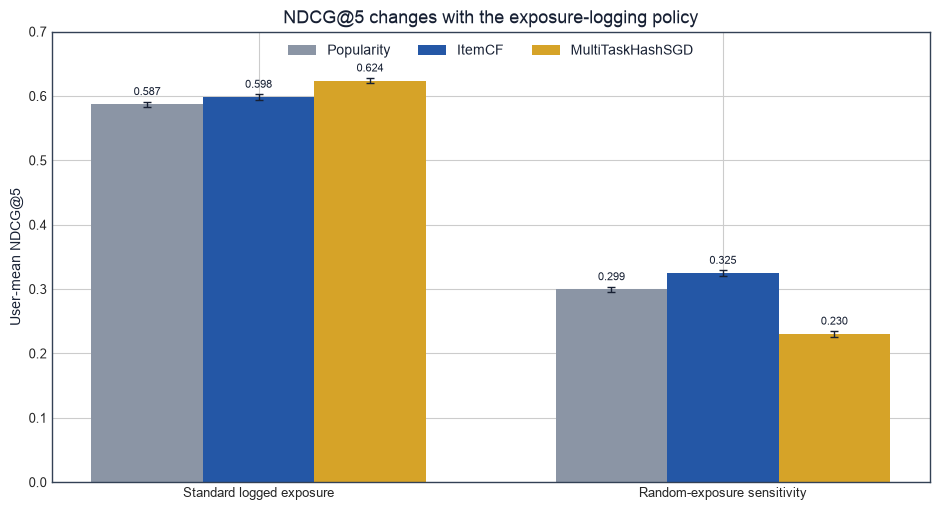

,split,model,ndcg_at_5,ndcg_at_5_ci_low,ndcg_at_5_ci_high,auc_long_view,ecr_at_5,content_coverage_at_10
3,standard_test,Popularity,0.586920,0.582685,0.590904,0.613845,0.437446,0.789514
4,standard_test,ItemCF,0.598259,0.593780,0.602336,0.615314,0.444437,0.815422
5,standard_test,MultiTaskHashSGD,0.623576,0.619406,0.627442,0.705298,0.459287,0.884869
6,random_sensitivity,Popularity,0.299303,0.294731,0.303715,0.606748,0.199924,0.968638
7,random_sensitivity,ItemCF,0.324732,0.320136,0.328950,0.617705,0.214092,0.972211
8,random_sensitivity,MultiTaskHashSGD,0.230270,0.225776,0.234362,0.621827,0.158073,0.973667


In [3]:
plot_data = metrics[metrics["split"].isin(["standard_test", "random_sensitivity"])].copy()
split_labels = {"standard_test": "Standard logged exposure", "random_sensitivity": "Random-exposure sensitivity"}
models = ["Popularity", "ItemCF", "MultiTaskHashSGD"]
x = np.arange(2)
width = 0.24
fig, ax = plt.subplots()
for index, model in enumerate(models):
    rows = plot_data[plot_data["model"] == model].set_index("split").loc[["standard_test", "random_sensitivity"]]
    values = rows["ndcg_at_5"].to_numpy()
    lower = values - rows["ndcg_at_5_ci_low"].to_numpy()
    upper = rows["ndcg_at_5_ci_high"].to_numpy() - values
    bars = ax.bar(x + (index - 1) * width, values, width, label=model, color=COLORS[model])
    ax.errorbar(x + (index - 1) * width, values, yerr=[lower, upper], fmt="none", ecolor="#172033", capsize=3, lw=1)
    ax.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=5, fontsize=8)
ax.set_title("NDCG@5 changes with the exposure-logging policy")
ax.set_ylabel("User-mean NDCG@5")
ax.set_xticks(x, [split_labels[key] for key in ["standard_test", "random_sensitivity"]])
ax.set_ylim(0, 0.70)
ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
plt.show()

display(plot_data[["split", "model", "ndcg_at_5", "ndcg_at_5_ci_low", "ndcg_at_5_ci_high", "auc_long_view", "ecr_at_5", "content_coverage_at_10"]])

### 2. 标准曝光上的效率与覆盖需同屏判断

MultiTaskHashSGD 的标准测试 NDCG@5、Top-5 ECR 和 Coverage@10 同时高于两个简单基线。但这是对原策略已展示内容的再排序能力，不能推断它对未曝光内容的召回能力。

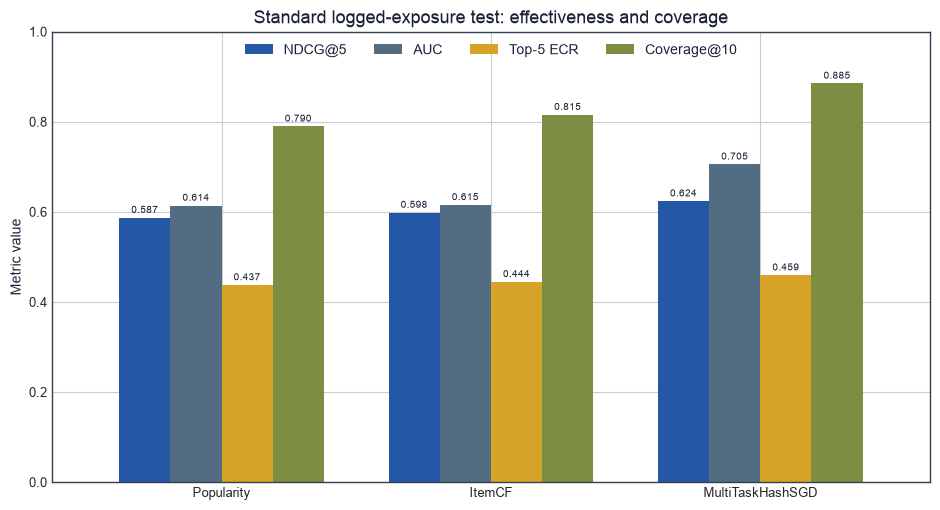

In [4]:
standard = metrics[metrics["split"] == "standard_test"].set_index("model").loc[models]
summary = standard[["ndcg_at_5", "auc_long_view", "ecr_at_5", "content_coverage_at_10"]].copy()
summary.columns = ["NDCG@5", "AUC", "Top-5 ECR", "Coverage@10"]
ax = summary.plot.bar(color=["#2457A6", "#526D82", "#D6A328", "#7C8E42"], width=0.76)
ax.set_title("Standard logged-exposure test: effectiveness and coverage")
ax.set_ylabel("Metric value")
ax.set_xlabel("")
ax.set_xticklabels(summary.index, rotation=0)
ax.set_ylim(0, 1.0)
ax.legend(frameon=False, ncol=4, loc="upper center")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7)
plt.tight_layout()
plt.show()

### 3. 供需与消费错配提供两类策略切口

- 标签 39 是“历史需求明显高于后续曝光”的首要候选，需进一步拆分为供给不足与分发不足。
- 标签 2 的曝光—消费差值最大，但规模较小；标签 12 差值较小但曝光规模更大。两者应分别形成策略假设，而不是直接下结论降权。

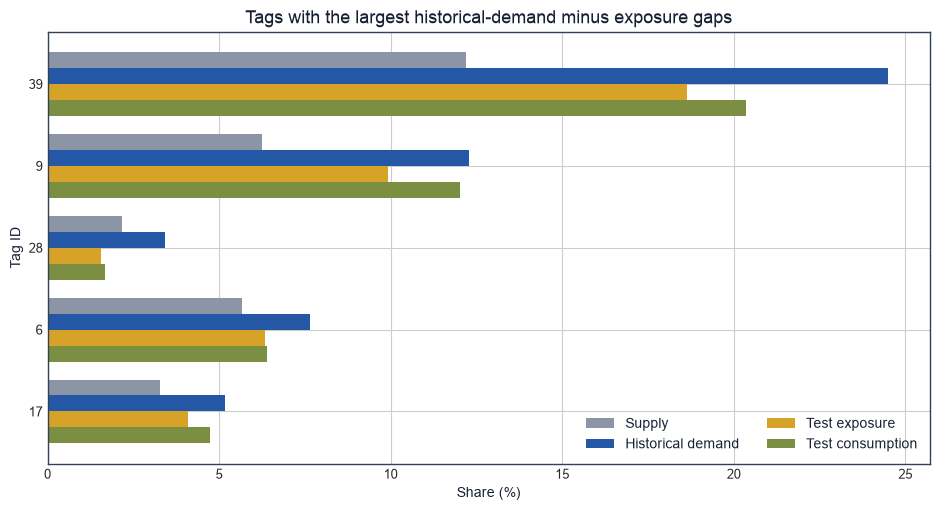

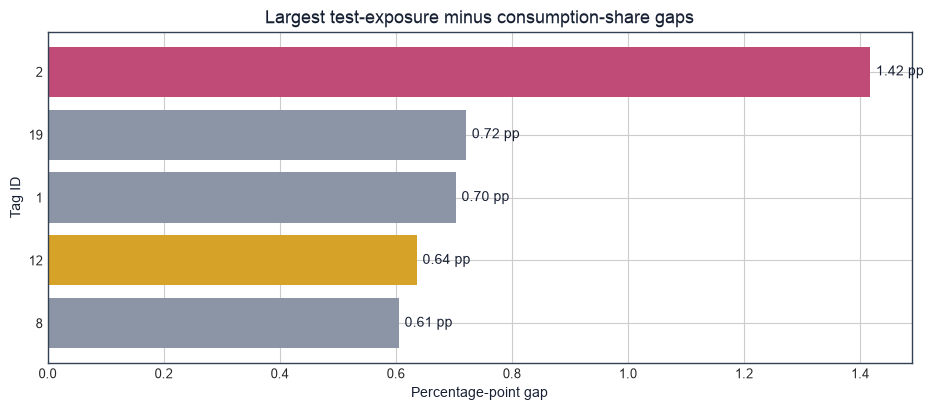

,tag_id,supply_share,demand_share,exposure_share,consumption_share,supply_gap,distribution_gap,consumption_gap
0,39,0.121966,0.244937,0.186448,0.203495,0.122971,0.058489,-0.017046
4,12,0.045943,0.054643,0.076072,0.069706,0.008700,-0.021429,0.006365
16,2,0.043249,0.010984,0.028157,0.013980,-0.032266,-0.017173,0.014177


In [5]:
focus_ids = ["39", "9", "28", "6", "17"]
focus = tags.set_index("tag_id").loc[focus_ids, ["supply_share", "demand_share", "exposure_share", "consumption_share"]] * 100
focus.columns = ["Supply", "Historical demand", "Test exposure", "Test consumption"]
ax = focus.plot.barh(color=["#8B95A5", "#2457A6", "#D6A328", "#7C8E42"], width=0.78)
ax.set_title("Tags with the largest historical-demand minus exposure gaps")
ax.set_xlabel("Share (%)")
ax.set_ylabel("Tag ID")
ax.invert_yaxis()
ax.legend(frameon=False, ncol=2, loc="lower right")
plt.tight_layout()
plt.show()

efficiency = tags[tags["exposure_share"] >= 0.002].nlargest(5, "consumption_gap").copy()
efficiency["gap_pp"] = efficiency["consumption_gap"] * 100
colors = ["#C04B76" if tag == "2" else "#D6A328" if tag == "12" else "#8B95A5" for tag in efficiency["tag_id"]]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
bars = ax.barh(efficiency["tag_id"].astype(str), efficiency["gap_pp"], color=colors)
ax.set_title("Largest test-exposure minus consumption-share gaps")
ax.set_xlabel("Percentage-point gap")
ax.set_ylabel("Tag ID")
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{value:.2f} pp" for value in efficiency["gap_pp"]], padding=4)
plt.tight_layout()
plt.show()

display(tags[tags["tag_id"].isin(["2", "12", "39"])])

### 4. 日级波动与护栏基线

日级走势用于发现异常和后续实验分层，不把自然波动解释成策略效果。护栏同时保留重复曝光和作者集中度，防止优化只追求短期消费。

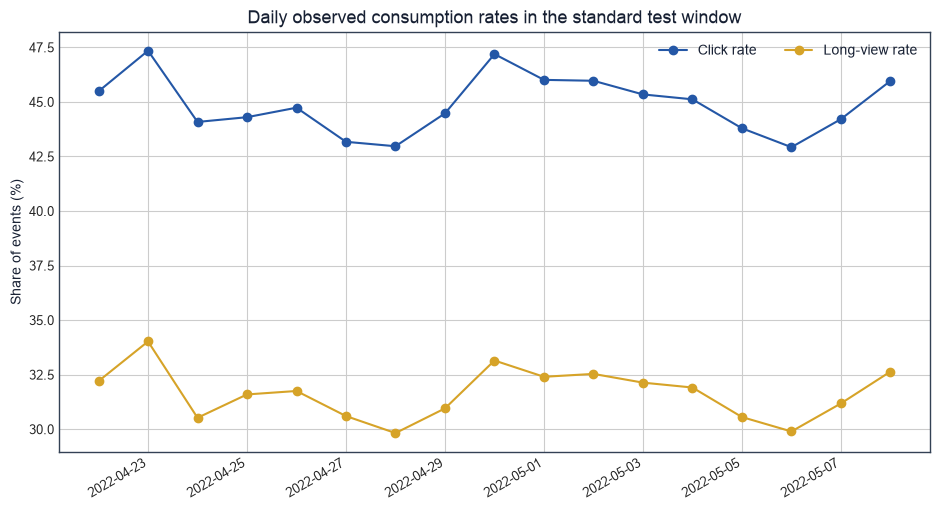

,guardrail,value
0,Same-video repeat rate (user-day),0.60%
1,Same-author repeat rate (user-day),0.72%
2,Users with video repeats,5.90%
3,Users with author repeats,6.90%
4,Top-10 author exposure share,4.33%
5,Top-100 author exposure share,22.41%


Author exposure HHI: 0.000958


In [6]:
daily["date_label"] = pd.to_datetime(daily["date"].astype(str), format="%Y%m%d")
fig, ax = plt.subplots()
ax.plot(daily["date_label"], daily["click_rate"] * 100, marker="o", label="Click rate", color="#2457A6")
ax.plot(daily["date_label"], daily["long_view_rate"] * 100, marker="o", label="Long-view rate", color="#D6A328")
ax.set_title("Daily observed consumption rates in the standard test window")
ax.set_ylabel("Share of events (%)")
ax.set_xlabel("")
ax.legend(frameon=False, ncol=2)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()

guardrail_table = pd.DataFrame([
    {"guardrail": "Same-video repeat rate (user-day)", "value": guardrails["same_video_repeat_rate_user_day"]},
    {"guardrail": "Same-author repeat rate (user-day)", "value": guardrails["same_author_repeat_rate_user_day"]},
    {"guardrail": "Users with video repeats", "value": guardrails["users_with_video_repeat_rate"]},
    {"guardrail": "Users with author repeats", "value": guardrails["users_with_author_repeat_rate"]},
    {"guardrail": "Top-10 author exposure share", "value": guardrails["top_10_author_exposure_share"]},
    {"guardrail": "Top-100 author exposure share", "value": guardrails["top_100_author_exposure_share"]},
])
display(guardrail_table.assign(value=guardrail_table["value"].map(lambda x: f"{x:.2%}")))
print(f"Author exposure HHI: {guardrails['author_hhi']:.6f}")

## Leakage test

特征只允许使用身份、请求时刻或上传时已知的信息。结果字段、播放时长结果和缺少事件日期的整月统计表均禁止进入模型；负控特征必须被拒绝，否则整个运行标记为无效。

In [7]:
display(pd.DataFrame([
    {"check": name, "status": "PASS" if passed else "FAIL"}
    for name, passed in leakage["checks"].items()
]))
print("Injected feature:", leakage["injected_feature"]["name"])
print("Rejected by:", ", ".join(leakage["injected_feature_failures"]))
assert set(leakage["injected_feature_failures"]) >= {"forbidden_source", "invalid_availability", "outcome_leakage"}

,check,status
0,train_ends_before_validation,PASS
1,validation_ends_before_test,PASS
2,configured_boundaries_match,PASS
3,no_future_upload_metadata,PASS
4,allowed_feature_specs_pass,PASS
5,forbidden_outcomes_absent_from_features,PASS
6,injected_future_feature_rejected,PASS


Injected feature: future_test_long_view_rate
Rejected by: forbidden_source, invalid_availability, outcome_leakage


## Takeaways

1. **Gate 3 可通过，但必须带条件。** 时间切分、三类基线、泄漏负控、供需诊断和独立复算已经闭环。
2. **最重要的结论不是“复杂模型赢了”。** 标准与随机曝光上的模型排序反转，说明日志采样机制会改变离线判断；Gate 4 必须用双日志敏感性而非单一排行榜。
3. **策略问题已可落到对象和机制。** 标签 39 对应供给／分发缺口假设；标签 2 与 12 对应不同规模的消费效率假设，下一步需做人群与场景切片。
4. **产品决策与模型指标分层。** NDCG、AUC 用于排序诊断，ECR、覆盖、重复和集中度用于业务取舍；没有线上随机实验时，不输出“上线收益”。
5. **Gate 4 最小任务。** 设计可配置重排策略，在同一候选、同一时间窗下报告绝对差、相对差、用户级区间与全部护栏，并形成实验卡与停止规则。